In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / "data" / "raw").exists() else cwd.parent
assert (ROOT / "data" / "raw").exists(), f"Cannot find data/raw from {cwd}"

SPOT_DIR = ROOT / "data" / "raw" / "1a ko" / "1382" / "Spot 1"
#TODO [1, 13] ou [2, 14]
DAYS = [1, 13]
OUTPUT_DIR = ROOT / "data" / "preprocessed" / "objectif1"
print("Project:", ROOT)
print("Source:", SPOT_DIR)
assert SPOT_DIR.is_dir(), f"Missing folder: {SPOT_DIR}"

Project: /Users/Tommyling/Documents/IAA/IAA-noradrenaline
Source: /Users/Tommyling/Documents/IAA/IAA-noradrenaline/data/raw/1a ko/1382/Spot 1


In [9]:
def load_npy_dict(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(path)
    obj = np.load(path, allow_pickle=True)
    try:
        data = obj.item()
    finally:
        if hasattr(obj, "close"):
            obj.close()
    if not isinstance(data, dict):
        raise TypeError(f"Expected dict in {path}, got {type(data)}")
    return data

def load_session(spot_dir: Path, day: int) -> dict:
    lever_dict = load_npy_dict(spot_dir / f"D{day}_lever.npy")
    imaging_dict = load_npy_dict(spot_dir / f"D{day}_2PHData.npy")
    if "lever_2p" not in lever_dict or "fluo" not in imaging_dict:
        raise KeyError(f"D{day}: available keys: lever={list(lever_dict)}, imaging={list(imaging_dict)}")

    lever_2p = np.asarray(lever_dict["lever_2p"], dtype=float)
    fluo = np.asarray(imaging_dict["fluo"], dtype=float)

    # Remove the last 500 buffer frames
    lever_2p = lever_2p[:, :-500]
    fluo = fluo[:, :-500]

    if lever_2p.ndim != 2 or fluo.ndim != 2:
        raise ValueError(f"D{day}: expected 2D arrays, got {lever_2p.shape} and {fluo.shape}")
    if lever_2p.shape[1] != fluo.shape[1]:
        raise ValueError(f"D{day}: time lengths differ: lever {lever_2p.shape}, fluo {fluo.shape}")
    return {"day": day, "lever_2p": lever_2p, "fluo": fluo}

sessions = {day: load_session(SPOT_DIR, day) for day in DAYS}
for day, session in sessions.items():
    print(f"D{day}: fluo {session['fluo'].shape}; lever_2p {session['lever_2p'].shape}")

D1: fluo (415, 6000); lever_2p (5, 6000)
D13: fluo (236, 6000); lever_2p (5, 6000)


In [10]:
def quality_report(day, session):
    rows = []
    for name in ("fluo", "lever_2p"):
        arr = session[name]
        rows.append({"day": f"D{day}", "array": name, "shape": str(arr.shape),
                     "nan_count": int(np.isnan(arr).sum()),
                     "nan_percent": round(100 * np.isnan(arr).mean(), 3),
                     "inf_count": int(np.isinf(arr).sum()),
                     "all_nan_rows": int(np.isnan(arr).all(axis=1).sum())})
    return rows

report = pd.DataFrame([row for day, s in sessions.items() for row in quality_report(day, s)])
display(report)
for day, s in sessions.items():
    print(f"D{day} lever_2p NaNs by position:", np.isnan(s['lever_2p']).sum(axis=1))
    print(f"D{day} lever_2p first 10 values by position:", s['lever_2p'][:, :10])

,day,array,shape,nan_count,nan_percent,inf_count,all_nan_rows
0,D1,fluo,"(415, 6000)",0,0.00,0,0
1,D1,lever_2p,"(5, 6000)",1515,5.05,0,0
2,D13,fluo,"(236, 6000)",0,0.00,0,0
3,D13,lever_2p,"(5, 6000)",1395,4.65,0,0


D1 lever_2p NaNs by position: [306 298 300 302 309]
D1 lever_2p first 10 values by position: [[         nan 535.44871795 530.74683544 515.17948718 510.56962025
  507.35897436 509.01265823 511.74358974 525.48717949 540.14285714]
 [536.         534.98717949 529.01265823 512.58974359 510.97468354
  507.26923077 509.01265823 513.19230769 527.03076923 540.        ]
 [535.88461538 534.64102564 526.98734177 510.79487179 510.26582278
  507.66666667 509.08860759 514.62025316 529.64705882 540.09090909]
 [535.84615385 534.26923077 524.51898734 509.61538462 509.43037975
  508.12658228 509.1025641  516.88607595 531.94736842 540.2826087 ]
 [535.69230769 533.78205128 521.51898734 509.2278481  508.55128205
  508.55696203 509.19230769 520.27848101 532.84       540.3220339 ]]
D13 lever_2p NaNs by position: [282 277 280 279 277]
D13 lever_2p first 10 values by position: [[         nan 538.01282051 538.25316456 538.29487179 538.98734177
  543.88461538 574.89873418 551.05063291 545.19230769 544.15189873]
 

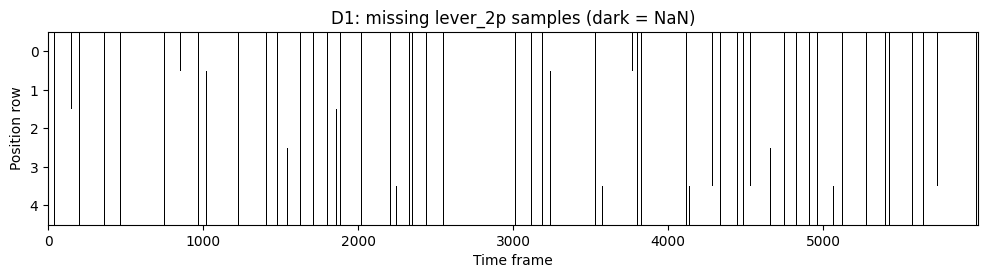

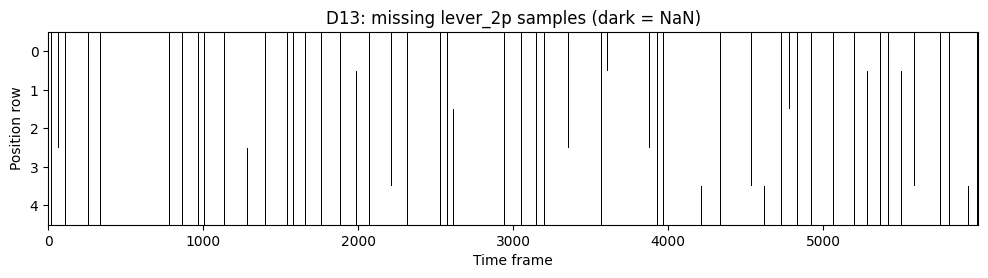

In [11]:
for day, s in sessions.items():
    fig, ax = plt.subplots(figsize=(12, 2.5))
    ax.imshow(np.isnan(s["lever_2p"]), aspect="auto", interpolation="nearest", cmap="gray_r")
    ax.set(title=f"D{day}: missing lever_2p samples (dark = NaN)", xlabel="Time frame", ylabel="Position row")
    ax.set_yticks(range(s["lever_2p"].shape[0]))
    plt.show()

In [12]:
SAVE = True  # Change to True after checking the diagnostics
if SAVE:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for day, s in sessions.items():
        out = OUTPUT_DIR / f"mouse1382_spot1_D{day}.npz"
        np.savez_compressed(out, fluo=s["fluo"], lever_2p=s["lever_2p"])
        print("Saved:", out)

Saved: /Users/Tommyling/Documents/IAA/IAA-noradrenaline/data/preprocessed/objectif1/mouse1382_spot1_D1.npz
Saved: /Users/Tommyling/Documents/IAA/IAA-noradrenaline/data/preprocessed/objectif1/mouse1382_spot1_D13.npz
